# Level 5 · Real-Time Advanced Predictive Analytics Applications — lab notebook
**BIM41 Advanced Predictive Analytics · Dr. Sridevi Tandley · Bharathidasan Institute of Management**

Three applications from the syllabus, each ending in a **commercial recommendation**, plus the analysis traps to avoid.

| Part | Application | Business question |
|---|---|---|
| 1 | Market basket analysis (Apriori) | Which products should we place, bundle or promote together? |
| 2 | Conjoint analysis (course car example) | What is each feature worth, and what share would a new car win? |
| 3 | Churn analysis (IBM Telco data) | Whom should we save first, within the budget? |
| 4 | Analysis traps | Accuracy, outliers, overfitting and calibration |

Market-basket and conjoint data are **synthetic** (fixed seeds). Churn uses IBM's public Telco sample, with a synthetic fallback if you are offline.

In [1]:
# Run this once if a library is missing (Google Colab has most of them). Tested November 2026.
# %pip install -q mlxtend statsmodels scikit-learn
import warnings, inspect
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); plt.rcParams["figure.figsize"] = (10, 4)
print("pandas", pd.__version__)

pandas 2.3.3


## Part 1 · Market basket analysis
5,000 supermarket baskets with a few associations planted on purpose. We find them with **Apriori** and read three numbers:
* **Support**: how often the itemset occurs. **Confidence**: P(consequent | antecedent).
* **Lift** = confidence ÷ support of the consequent. Lift > 1 means the items go together more than chance; lift ≈ 1 means no real link.

In [2]:
rng = np.random.default_rng(5)
base = {"milk": .45, "bread": .30, "tea": .28, "rice": .25, "eggs": .22, "chips": .18, "sugar": .15,
        "onions": .30, "detergent": .10, "diapers": .05}
rules_planted = [("tea", "biscuits", .65), ("bread", "butter", .55), ("rice", "dal", .60), ("chips", "cola", .50),
                 ("diapers", "baby wipes", .70), ("tea", "sugar", .35)]
baskets = []
for _ in range(5000):
    b = {item for item, p in base.items() if rng.random() < p}
    for a, c, p in rules_planted:
        if a in b and rng.random() < p:
            b.add(c)
    if rng.random() < .06: b.add("biscuits")        # some biscuits are bought without tea
    if b: baskets.append(sorted(b))
print(len(baskets), "baskets | example:", baskets[:3])

4683 baskets | example: [['detergent', 'eggs', 'onions'], ['detergent', 'milk'], ['baby wipes', 'bread', 'butter', 'diapers', 'onions']]


In [3]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)
freq = apriori(onehot, min_support=0.02, use_colnames=True)
# mlxtend >= 0.23.2 takes num_itemsets (the number of baskets); older versions do not have it
kw = {"num_itemsets": len(onehot)} if "num_itemsets" in inspect.signature(association_rules).parameters else {}
rules = association_rules(freq, metric="lift", min_threshold=1.2, **kw)
rules["rule"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s))) + " → " + rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
pairs = rules[(rules["antecedents"].apply(len) == 1) & (rules["consequents"].apply(len) == 1)]
top = pairs.sort_values("lift", ascending=False)[["rule", "support", "confidence", "lift"]].head(8)
print(len(freq), "frequent itemsets |", len(rules), "rules with lift ≥ 1.2 | showing one-to-one rules")
top

193 frequent itemsets | 378 rules with lift ≥ 1.2 | showing one-to-one rules


,rule,support,confidence,lift
0,baby wipes → diapers,0.044,1.000,16.148
1,diapers → baby wipes,0.044,0.707,16.148
9,cola → chips,0.097,1.000,5.395
8,chips → cola,0.097,0.525,5.395
10,rice → dal,0.156,0.580,3.708
11,dal → rice,0.156,1.000,3.708
6,butter → bread,0.168,1.000,3.216
7,bread → butter,0.168,0.540,3.216


In [4]:
# The confidence trap: milk is in 45% of baskets, so "X → milk" looks confident without meaning anything
all_rules = association_rules(freq, metric="confidence", min_threshold=0.0, **kw)
milk = all_rules[all_rules["consequents"] == frozenset({"milk"})].sort_values("confidence", ascending=False)
milk = milk.assign(rule=milk["antecedents"].apply(lambda s: ", ".join(sorted(s))) + " → milk")
print(milk[["rule", "confidence", "lift"]].head(4).to_string(index=False))
print("\nHigh confidence, lift ≈ 1: these customers buy milk at the same rate as everyone else. Not a rule to act on.")

                      rule  confidence  lift
     biscuits, rice → milk       0.516 1.051
          eggs, tea → milk       0.503 1.025
biscuits, eggs, tea → milk       0.497 1.013
        rice, sugar → milk       0.497 1.011

High confidence, lift ≈ 1: these customers buy milk at the same rate as everyone else. Not a rule to act on.


## Part 2 · Conjoint analysis: the course car example
Attributes and levels follow the course deck: brand origin, body type, engine type and price.
The **baseline car** is Japanese, Sedan, Gasoline, \$20,000 (part-worths fixed at 0).

The course deck shows one respondent's part-worths. Here we **generate synthetic ratings from those part-worths** for 15 profiles
(the course also used 15), then check that regression recovers them. That is how you test an analysis before trusting it on real data.

> The course deck lists American = 0.33 and an intercept of 4.20, but its worked choice example uses 0.37 and 4.21. The importances it reports
> (brand range 1.17) only work with 0.33, so 0.33 and 4.20 are used here.

In [5]:
true_pw = {"intercept": 4.20,
           "brand": {"Japanese": 0, "American": 0.33, "European": -0.84},
           "body": {"Sedan": 0, "SUV": 0.96, "Sports car": -0.10},
           "engine": {"Gasoline": 0, "Hybrid": 1.78, "Electric": 0.86},
           "price": {"$20,000": 0, "$30,000": -0.58, "$40,000": -1.20}}
levels = {a: list(v) for a, v in true_pw.items() if a != "intercept"}

# 15 profiles: the L9 orthogonal array (balanced main effects) plus 6 more distinct profiles
L9 = [(0,0,0,0), (0,1,1,1), (0,2,2,2), (1,0,1,2), (1,1,2,0), (1,2,0,1), (2,0,2,1), (2,1,0,2), (2,2,1,0)]
rng = np.random.default_rng(15)
extra = set()
while len(extra) < 6:
    p = tuple(int(x) for x in rng.integers(0, 3, 4))
    if p not in L9: extra.add(p)
design = pd.DataFrame([{a: levels[a][i] for a, i in zip(levels, p)} for p in L9 + sorted(extra)])
utility = true_pw["intercept"] + sum(design[a].map(true_pw[a]) for a in levels)
design["rating"] = (utility + rng.normal(0, 0.10, len(design))).round(2)
design

,brand,body,engine,price,rating
0,Japanese,Sedan,Gasoline,"$20,000",4.23
1,Japanese,SUV,Hybrid,"$30,000",6.50
2,Japanese,Sports car,Electric,"$40,000",3.81
3,American,Sedan,Hybrid,"$40,000",5.28
4,American,SUV,Electric,"$20,000",6.41
5,American,Sports car,Gasoline,"$30,000",3.83
6,European,Sedan,Electric,"$30,000",3.49
7,European,SUV,Gasoline,"$40,000",2.96
8,European,Sports car,Hybrid,"$20,000",5.06
9,Japanese,SUV,Gasoline,"$20,000",5.23


In [6]:
import statsmodels.formula.api as smf

ols = smf.ols("rating ~ C(brand, Treatment('Japanese')) + C(body, Treatment('Sedan'))"
              " + C(engine, Treatment('Gasoline')) + C(price, Treatment('$20,000'))", data=design).fit()
est = ols.params.rename(lambda k: k.split("[T.")[-1].rstrip("]") if "[T." in k else k).round(2)
course = {"Intercept": true_pw["intercept"], **{l: true_pw[a][l] for a in levels for l in levels[a][1:]}}
print(pd.DataFrame({"estimated": est, "course deck": pd.Series(course)}))
print(f"R² = {ols.rsquared:.3f}")

            estimated  course deck
$30,000         -0.65        -0.58
$40,000         -1.22        -1.20
American         0.33         0.33
Electric         0.93         0.86
European        -0.98        -0.84
Hybrid           1.93         1.78
Intercept        4.24         4.20
SUV              0.95         0.96
Sports car      -0.13        -0.10
R² = 0.999


In [7]:
# Attribute importance = range of its part-worths ÷ sum of all ranges
pw = {a: {l: (0.0 if l == levels[a][0] else est[l]) for l in levels[a]} for a in levels}
ranges = pd.Series({a: max(v.values()) - min(v.values()) for a, v in pw.items()})
importance = (ranges / ranges.sum()).round(3)
print(pd.DataFrame({"range": ranges.round(2), "importance": importance}))
ideal = {a: max(v, key=v.get) for a, v in pw.items()}
print("Ideal car for this respondent:", ideal)

        range  importance
brand    1.31       0.236
body     1.08       0.195
engine   1.93       0.348
price    1.22       0.220
Ideal car for this respondent: {'brand': 'American', 'body': 'SUV', 'engine': 'Hybrid', 'price': '$20,000'}


In [8]:
# Predict choice among the course's three cars, then willingness to pay for Hybrid
cars = {"A": ("Japanese", "Sedan", "Hybrid", "$20,000"),
        "B": ("European", "Sports car", "Gasoline", "$40,000"),
        "C": ("American", "SUV", "Gasoline", "$30,000")}
value = {k: est["Intercept"] + sum(pw[a][lvl] for a, lvl in zip(levels, v)) for k, v in cars.items()}
print({k: round(v, 2) for k, v in value.items()}, "→ chooses", max(value, key=value.get))
util_per_dollar = (pw["price"]["$20,000"] - pw["price"]["$40,000"]) / 20000
print(f"Hybrid is worth about ${pw['engine']['Hybrid'] / util_per_dollar:,.0f} to this respondent "
      f"(linear between $20k and $40k: a rough guide, not a price)")

{'A': np.float64(6.17), 'B': np.float64(1.91), 'C': np.float64(4.87)} → chooses A
Hybrid is worth about $31,639 to this respondent (linear between $20k and $40k: a rough guide, not a price)


In [9]:
# From one person to a market: 400 synthetic respondents whose part-worths vary (s.d. 1.0) around the course values
n = 400
market = []
for _ in range(n):
    person = {a: {l: (0.0 if l == levels[a][0] else true_pw[a][l] + rng.normal(0, 1.0)) for l in levels[a]} for a in levels}
    market.append({k: sum(person[a][lvl] for a, lvl in zip(levels, v)) for k, v in cars.items()})
U = pd.DataFrame(market)
first_choice = U.idxmax(axis=1).value_counts(normalize=True).reindex(list(cars)).fillna(0)
logit_share = np.exp(U).div(np.exp(U).sum(axis=1), axis=0).mean()
print(pd.DataFrame({"first-choice share": first_choice.round(3), "logit share": logit_share.round(3)}))
print("Course deck (its own respondent sample): A 47.7%, B 32.5%, C 19.8% — ours differ because the sample is synthetic.")

   first-choice share  logit share
A               0.718        0.628
B               0.010        0.044
C               0.272        0.328
Course deck (its own respondent sample): A 47.7%, B 32.5%, C 19.8% — ours differ because the sample is synthetic.


In [10]:
# What-if: cut car C's price to $20,000. Who loses share?
U2 = U.copy()
U2["C"] = U["C"] - pw["price"]["$30,000"] + pw["price"]["$20,000"]
shift = pd.DataFrame({"before": first_choice, "after price cut": U2.idxmax(axis=1).value_counts(normalize=True).reindex(list(cars)).fillna(0)})
shift.round(3)

,before,after price cut
A,0.718,0.595
B,0.010,0.008
C,0.272,0.398


## Part 3 · Churn analysis: whom do we save first?
IBM's public Telco sample (7,043 customers). The commercial question is not "what is the accuracy?" but **"which customers should get the retention offer,
given the budget?"**

In [11]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

def synthetic_telco(n=7043, seed=8):
    r = np.random.default_rng(seed)
    t = pd.DataFrame({"tenure": r.integers(0, 73, n), "MonthlyCharges": r.normal(65, 30, n).clip(18, 120).round(2),
                      "Contract": r.choice(["Month-to-month", "One year", "Two year"], n, p=[.55, .21, .24]),
                      "InternetService": r.choice(["DSL", "Fiber optic", "No"], n, p=[.34, .44, .22]),
                      "TechSupport": r.choice(["Yes", "No"], n, p=[.3, .7]),
                      "PaymentMethod": r.choice(["Electronic check", "Mailed check", "Bank transfer (automatic)",
                                                 "Credit card (automatic)"], n)})
    logit = (-1.2 - 0.04 * t.tenure + 1.3 * (t.Contract == "Month-to-month") + 0.6 * (t.InternetService == "Fiber optic")
             - 0.5 * (t.TechSupport == "Yes") + 0.5 * (t.PaymentMethod == "Electronic check") + 0.01 * t.MonthlyCharges)
    t["Churn"] = np.where(r.random(n) < 1 / (1 + np.exp(-logit)), "Yes", "No")
    t["TotalCharges"] = (t.tenure * t.MonthlyCharges).round(2)
    return t

try:
    telco = pd.read_csv(URL); source = "IBM Telco sample (GitHub)"
except Exception as e:
    telco = synthetic_telco(); source = f"synthetic fallback ({type(e).__name__})"
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce").fillna(0)
y = (telco["Churn"] == "Yes").astype(int)
print(source, telco.shape, f"| churn rate {y.mean():.1%}")

IBM Telco sample (GitHub) (7043, 21) | churn rate 26.5%


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score

num = ["tenure", "MonthlyCharges", "TotalCharges"]
cat = [c for c in ["Contract", "InternetService", "TechSupport", "PaymentMethod", "PaperlessBilling",
                   "OnlineSecurity", "SeniorCitizen", "Partner", "Dependents"] if c in telco.columns]
X = telco[num + cat].astype({c: str for c in cat})
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
prep = ColumnTransformer([("num", StandardScaler(), num),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
models = {"Logistic regression": make_pipeline(prep, LogisticRegression(max_iter=2000)),
          "Gradient boosting": make_pipeline(ColumnTransformer([("num", "passthrough", num),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)]),
                          HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0))}
scores = {}
for name, mdl in models.items():
    p = mdl.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    scores[name] = {"ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                    "accuracy @0.5": accuracy_score(y_te, p >= 0.5)}
scores["Predict 'nobody churns'"] = {"ROC-AUC": 0.5, "PR-AUC": y_te.mean(), "accuracy @0.5": 1 - y_te.mean()}
pd.DataFrame(scores).T.round(3)

,ROC-AUC,PR-AUC,accuracy @0.5
Logistic regression,0.841,0.642,0.802
Gradient boosting,0.839,0.657,0.799
Predict 'nobody churns',0.500,0.265,0.735


In [13]:
# Decile lift: rank customers by risk, split into 10 equal groups
proba = models["Logistic regression"].predict_proba(X_te)[:, 1]
lift = pd.DataFrame({"p": proba, "churn": y_te.values}).sort_values("p", ascending=False)
lift["decile"] = np.arange(len(lift)) * 10 // len(lift) + 1
table = lift.groupby("decile").agg(customers=("churn", "size"), churners=("churn", "sum"), churn_rate=("churn", "mean"))
table["lift"] = (table["churn_rate"] / y_te.mean()).round(2)
table["cum. share of churners"] = (table["churners"].cumsum() / table["churners"].sum()).round(2)
table

,customers,churners,churn_rate,lift,cum. share of churners
decile,,,,,
1,212,155,0.731,2.75,0.28
2,211,128,0.607,2.28,0.50
3,211,89,0.422,1.59,0.66
4,212,66,0.311,1.17,0.78
5,211,50,0.237,0.89,0.87
6,211,32,0.152,0.57,0.93
7,212,27,0.127,0.48,0.98
8,211,8,0.038,0.14,0.99
9,211,4,0.019,0.07,1.00


Best plan: target the top 936 of 2113 customers (44%), expected profit ₹936,000 on this test set


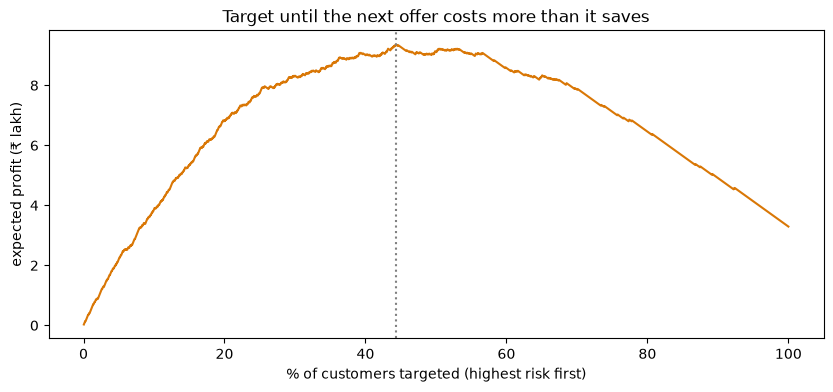

In [14]:
# Value-based targeting. Every number below is an ASSUMPTION for illustration: replace with your own.
CLV, OFFER_COST, SAVE_RATE = 12000, 800, 0.30          # ₹ value of a saved customer, ₹ per offer, share of churners saved
order = np.argsort(-proba)
expected_profit = [(y_te.values[order[:k]].sum() * SAVE_RATE * CLV - k * OFFER_COST) for k in range(1, len(order) + 1)]
best_k = int(np.argmax(expected_profit)) + 1
print(f"Best plan: target the top {best_k} of {len(order)} customers ({best_k/len(order):.0%}), "
      f"expected profit ₹{max(expected_profit):,.0f} on this test set")
plt.plot(np.arange(1, len(order) + 1) / len(order) * 100, np.array(expected_profit) / 1e5, color="#d97706")
plt.axvline(best_k / len(order) * 100, ls=":", color="gray"); plt.xlabel("% of customers targeted (highest risk first)")
plt.ylabel("expected profit (₹ lakh)"); plt.title("Target until the next offer costs more than it saves"); plt.show()

## Part 4 · Analysis traps, demonstrated

In [15]:
# Trap 1 · Outliers: run the analysis two ways and compare (the course deck's advice)
r = np.random.default_rng(2)
spend = r.normal(5000, 800, 300); visits = spend / 500 + r.normal(0, 1, 300)
spend_err = spend.copy(); spend_err[:3] = [95000, 88000, 91000]          # three data-entry errors
z = (spend_err - spend_err.mean()) / spend_err.std()
q1, q3 = np.percentile(spend_err, [25, 75]); iqr_flag = (spend_err < q1 - 1.5 * (q3 - q1)) | (spend_err > q3 + 1.5 * (q3 - q1))
print(f"Flagged: z-score>3: {(np.abs(z) > 3).sum()}, IQR rule: {iqr_flag.sum()}")
print(f"Correlation visits~spend  with errors: {np.corrcoef(visits, spend_err)[0, 1]:.2f} | errors removed: "
      f"{np.corrcoef(visits[~iqr_flag], spend_err[~iqr_flag])[0, 1]:.2f}")

Flagged: z-score>3: 3, IQR rule: 3
Correlation visits~spend  with errors: 0.12 | errors removed: 0.86


In [16]:
# Trap 2 · Curve fitting: training error keeps falling, validation error turns back up
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
x = np.sort(r.uniform(0, 10, 60)); yv = np.sin(x) + r.normal(0, 0.3, 60)
rows = []
for d in [1, 3, 5, 9, 15]:
    mdl = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression())
    train_mse = np.mean((mdl.fit(x[:, None], yv).predict(x[:, None]) - yv) ** 2)
    cv_mse = -cross_val_score(mdl, x[:, None], yv, cv=KFold(5, shuffle=True, random_state=0),
                             scoring="neg_mean_squared_error").mean()
    rows.append({"degree": d, "train MSE": round(train_mse, 3), "cross-validated MSE": round(cv_mse, 3)})
pd.DataFrame(rows)

,degree,train MSE,cross-validated MSE
0,1,0.459,0.483
1,3,0.286,0.358
2,5,0.098,0.188
3,9,0.081,0.143
4,15,0.081,0.540


In [17]:
# Trap 3 · Scores that are not probabilities: check calibration before you multiply by money
from sklearn.calibration import calibration_curve
gb_p = models["Gradient boosting"].predict_proba(X_te)[:, 1]
for name, p in [("Logistic regression", proba), ("Gradient boosting", gb_p)]:
    frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=8, strategy="quantile")
    print(f"{name:<20} mean |predicted − observed| across bins: {np.mean(np.abs(frac_pos - mean_pred)):.3f}")

Logistic regression  mean |predicted − observed| across bins: 0.015
Gradient boosting    mean |predicted − observed| across bins: 0.011


### Capstone canvas (fill this in for your project)
1. **Business objective** — one measurable goal (e.g. reduce churn among high-value customers by 15% this year).
2. **Stakeholders and team** — who decides, who builds, who runs it.
3. **Data** — sources, quality checks, what is missing, how it is sampled.
4. **Quick victory** — the smallest model that proves value in weeks.
5. **Model and validation** — baseline first; business and technical evaluation.
6. **Deployment** — where the score is used, by whom, how often.
7. **Monitoring and update** — drift and error thresholds, retraining owner.
8. **Commercial recommendation** — the action, its expected value and its risk.